# Notebook 6: Sentiment Analysis of Consumer Financial Complaints

## Objective

This notebook applies pretrained transformer models to estimate the sentiment expressed in consumer complaint narratives.

The analysis will:

- compare suitable pretrained sentiment models;
- evaluate prediction distributions and confidence scores;
- measure agreement and disagreement between models;
- inspect a small number of predictions qualitatively;
- account for narratives exceeding transformer token limits;
- select one model for the final sentiment analysis;
- measure real sentiment volumes using the full narrative dataset;
- compare products fairly using the equal-product corpus.



## Dataset Roles

Two prepared datasets from Notebook 5 are used:

### 1. Full narrative dataset

- File: `full_narratives_prepared.csv`
- Size: 272,466 complaint narratives
- Purpose: estimate real complaint volumes and overall sentiment patterns.

### 2. Equal-product NLP corpus

- File: `equal_product_nlp_corpus.csv`
- Size: 52,975 complaint narratives
- Purpose: compare sentiment patterns fairly across products without results being dominated by products with more complaints.

The prepared `narrative_text` column is used directly. Text cleaning from Notebook 5 is not repeated.

## Methodology

The analysis follows five stages:

1. **Model comparison**

   Two pretrained models are tested on the same reproducible, product-balanced sample from the equal-product corpus.

2. **Long-narrative handling**

   Narratives exceeding a model's token limit are divided into overlapping token chunks. Sentiment probabilities from the chunks are aggregated to produce one prediction per complaint.

3. **Model diagnostics**

   Because human reference labels are unavailable, the models are compared using:

   - predicted sentiment distributions;
   - confidence-score distributions;
   - pairwise prediction agreement;
   - disagreement cases;
   - qualitative inspection of a small prediction sample;
   - suitability of each model's training domain.

4. **Final sentiment inference**

   After selecting the more suitable model, it is applied to the complete narrative dataset.

5. **Product comparison**

   - The full dataset is used for real complaint and sentiment volumes.
   - The equal-product corpus is used only for balanced product-level comparisons.

## Interpretation Note

This notebook uses pretrained models to generate sentiment predictions.

Because the complaint narratives do not have verified sentiment labels, model accuracy cannot be calculated directly. Confidence scores and agreement between models are therefore used as diagnostic indicators, not as proof of correctness.

The resulting sentiment labels are suitable for exploratory analysis of complaint patterns but should not be treated as verified human judgements.

## Pretrained Model Comparison

Two models with positive, neutral and negative output classes are considered.

| Model | Role in comparison | Domain advantage | Important limitation |
|---|---|---|---|
| `ProsusAI/finbert` | Finance-domain candidate | Trained on financial language and financial sentiment | Financial reports and news differ from first-person consumer complaints |
| `lxyuan/distilbert-base-multilingual-cased-sentiments-student` | General sentiment candidate | Efficient three-class sentiment model with broader language coverage | Not specifically trained on financial complaints |

Neither model is assumed to be correct automatically. The final choice will be based on domain suitability together with the empirical comparison results.

In [1]:
# Run only if Transformers is not already installed
%pip install -q transformers accelerate sentencepiece

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import random
import warnings

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

/Users/ishika/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


PyTorch version: 2.8.0
Device: cpu


In [31]:
# Change DATA_DIR only if the CSV files are stored in another folder
DATA_DIR = Path("/Users/ishika/Documents/AIProject/data/processed")

FULL_DATA_PATH = DATA_DIR / "full_narratives_prepared.csv"
EQUAL_DATA_PATH = DATA_DIR / "equal_product_nlp_corpus.csv"

TEXT_COL = "narrative_text"
PRODUCT_COL = "product"
ID_COL = "complaint_id"

MODEL_SPECS = {
    "finbert": {
        "model_name": "ProsusAI/finbert",
        "description": "Finance-domain sentiment model"
    },
    "general_distilbert": {
        "model_name": (
            "lxyuan/"
            "distilbert-base-multilingual-cased-sentiments-student"
        ),
        "description": "General three-class sentiment model"
    }
}

# Model-comparison sample: 250 narratives from each product
COMPARISON_SAMPLE_PER_PRODUCT = 250

# Long narratives will later be processed as overlapping token chunks
CHUNK_SIZE = 384
CHUNK_OVERLAP = 64
BATCH_SIZE = 16

print("Full dataset path:", FULL_DATA_PATH)
print("Equal-product dataset path:", EQUAL_DATA_PATH)
print("Models to compare:")

for key, specification in MODEL_SPECS.items():
    print(f"- {key}: {specification['model_name']}")

Full dataset path: /Users/ishika/Documents/AIProject/data/processed/full_narratives_prepared.csv
Equal-product dataset path: /Users/ishika/Documents/AIProject/data/processed/equal_product_nlp_corpus.csv
Models to compare:
- finbert: ProsusAI/finbert
- general_distilbert: lxyuan/distilbert-base-multilingual-cased-sentiments-student


## 2. Load and Validate the Prepared Datasets

Only the complaint ID, product and prepared narrative text are loaded for sentiment analysis.

The text is not cleaned or modified again. This section only confirms that the required columns and expected records are available.

In [7]:
REQUIRED_COLUMNS = [ID_COL, PRODUCT_COL, TEXT_COL]

full_narratives = pd.read_csv(
    FULL_DATA_PATH,
    usecols=REQUIRED_COLUMNS,
    dtype={ID_COL: "string"}
)

equal_product_corpus = pd.read_csv(
    EQUAL_DATA_PATH,
    usecols=REQUIRED_COLUMNS,
    dtype={ID_COL: "string"}
)

print("Full narrative dataset:", full_narratives.shape)
print("Equal-product corpus:", equal_product_corpus.shape)

Full narrative dataset: (272466, 3)
Equal-product corpus: (52975, 3)


In [8]:
validation_summary = pd.DataFrame({
    "check": [
        "Full narrative records",
        "Equal-product records",
        "Missing full narrative text",
        "Missing equal-corpus narrative text",
        "Duplicate complaint IDs in full data",
        "Duplicate complaint IDs in equal corpus",
        "Products in full data",
        "Products in equal corpus"
    ],
    "value": [
        len(full_narratives),
        len(equal_product_corpus),
        full_narratives[TEXT_COL].isna().sum(),
        equal_product_corpus[TEXT_COL].isna().sum(),
        full_narratives[ID_COL].duplicated().sum(),
        equal_product_corpus[ID_COL].duplicated().sum(),
        full_narratives[PRODUCT_COL].nunique(),
        equal_product_corpus[PRODUCT_COL].nunique()
    ]
})

display(validation_summary)

,check,value
0,Full narrative records,272466
1,Equal-product records,52975
2,Missing full narrative text,0
3,Missing equal-corpus narrative text,0
4,Duplicate complaint IDs in full data,0
5,Duplicate complaint IDs in equal corpus,0
6,Products in full data,5
7,Products in equal corpus,5


In [34]:
full_narratives[
    ["complaint_id", "product", "narrative_text"]
].to_csv(
    "full_sentiment_input.csv.gz",
    index=False,
    compression="gzip"
)

equal_product_corpus[
    ["complaint_id", "product"]
].to_csv(
    "equal_product_ids.csv.gz",
    index=False,
    compression="gzip"
)

In [35]:
print("Compressed files created:")
print(Path("full_sentiment_input.csv.gz").resolve())
print(Path("equal_product_ids.csv.gz").resolve())

Compressed files created:
/Users/ishika/Documents/AIProject/notebooks/full_sentiment_input.csv.gz
/Users/ishika/Documents/AIProject/notebooks/equal_product_ids.csv.gz


## 3. Create the Model-Comparison Sample

A reproducible sample is drawn from the equal-product corpus for comparing the two pretrained models.

The sample contains 100 randomly selected narratives from each of the five products, producing 500 narratives in total.

This sample is used only to compare:

- prediction distributions;
- model confidence;
- model agreement and disagreement;
- behaviour on long narratives;
- a small number of example predictions.

No narratives are manually labelled.

In [9]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Selected device:", DEVICE)

Selected device: mps


In [10]:
COMPARISON_SAMPLE_PER_PRODUCT = 100

comparison_sample = (
    equal_product_corpus
    .groupby(PRODUCT_COL, group_keys=False)
    .sample(
        n=COMPARISON_SAMPLE_PER_PRODUCT,
        random_state=SEED
    )
    .reset_index(drop=True)
    .copy()
)

comparison_sample["word_count"] = (
    comparison_sample[TEXT_COL]
    .str.split()
    .str.len()
)

print("Comparison sample shape:", comparison_sample.shape)

display(
    comparison_sample[PRODUCT_COL]
    .value_counts()
    .rename_axis("product")
    .reset_index(name="narratives")
)

Comparison sample shape: (500, 4)


,product,narratives
0,Checking or savings account,100
1,Credit card,100
2,Debt collection,100
3,"Money transfer, virtual currency, or money ser...",100
4,Mortgage,100


In [11]:
length_summary = (
    comparison_sample["word_count"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .round(2)
    .to_frame("word_count")
)

display(length_summary)

print(
    "Narratives longer than 400 words:",
    (comparison_sample["word_count"] > 400).sum()
)

,word_count
count,500.00
mean,196.33
std,217.98
min,10.00
25%,88.75
50%,131.50
75%,245.25
90%,372.20
95%,510.15
99%,1219.02


Narratives longer than 400 words: 37


## 4. Handling Long Narratives

Transformer models accept only a limited number of tokens. Word count is only an approximation because one word may be divided into multiple model tokens.

To avoid discarding the later parts of long complaints:

1. Each narrative is tokenized using the tokenizer belonging to the model.
2. Narratives longer than 384 tokens are divided into overlapping chunks.
3. Each chunk contains up to 384 content tokens.
4. Consecutive chunks overlap by 64 tokens to preserve context near chunk boundaries.
5. Every chunk is classified separately.
6. Chunk probabilities are later combined into one complaint-level prediction.

This preserves substantially more information than simply truncating every narrative at the model limit.

In [12]:
CHUNK_SIZE = 384
CHUNK_OVERLAP = 64

def count_required_chunks(
    token_count,
    chunk_size=CHUNK_SIZE,
    overlap=CHUNK_OVERLAP
):
    """Calculate how many chunks are required for one narrative."""
    
    if token_count <= chunk_size:
        return 1
    
    step_size = chunk_size - overlap
    
    return 1 + int(
        np.ceil((token_count - chunk_size) / step_size)
    )


def create_token_chunks(
    text,
    tokenizer,
    chunk_size=CHUNK_SIZE,
    overlap=CHUNK_OVERLAP
):
    """Convert one narrative into overlapping token chunks."""
    
    token_ids = tokenizer.encode(
        str(text),
        add_special_tokens=False
    )
    
    if len(token_ids) == 0:
        return [[]]
    
    step_size = chunk_size - overlap
    chunks = []
    
    for start in range(0, len(token_ids), step_size):
        chunk = token_ids[start:start + chunk_size]
        chunks.append(chunk)
        
        if start + chunk_size >= len(token_ids):
            break
    
    return chunks

In [13]:
token_chunk_summaries = []

for model_key, model_spec in MODEL_SPECS.items():
    
    print(f"Checking tokenizer: {model_key}")
    
    tokenizer = AutoTokenizer.from_pretrained(
        model_spec["model_name"]
    )
    
    token_counts = comparison_sample[TEXT_COL].apply(
        lambda text: len(
            tokenizer.encode(
                str(text),
                add_special_tokens=False
            )
        )
    )
    
    chunk_counts = token_counts.apply(count_required_chunks)
    
    token_chunk_summaries.append({
        "model": model_key,
        "minimum_tokens": int(token_counts.min()),
        "median_tokens": int(token_counts.median()),
        "maximum_tokens": int(token_counts.max()),
        "narratives_requiring_chunks": int(
            (chunk_counts > 1).sum()
        ),
        "maximum_chunks_for_one_narrative": int(
            chunk_counts.max()
        ),
        "total_chunks_for_500_narratives": int(
            chunk_counts.sum()
        )
    })
    
    del tokenizer

token_chunk_summary = pd.DataFrame(token_chunk_summaries)

display(token_chunk_summary)

Checking tokenizer: finbert


tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (839 > 512). Running this sequence through the model will result in indexing errors


,model,minimum_tokens,median_tokens,maximum_tokens,narratives_requiring_chunks,maximum_chunks_for_one_narrative,total_chunks_for_500_narratives
0,finbert,12,161,2909,83,9,637
1,general_distilbert,14,173,3127,94,10,660


## 5. Model 1: FinBERT Predictions

FinBERT is evaluated first because consumer complaints contain financial terminology.

Each narrative chunk receives probabilities for negative, neutral and positive sentiment. For narratives containing multiple chunks, the chunk probabilities are combined using a token-length-weighted average.

The final complaint-level label is the class with the highest aggregated probability. Its probability becomes the model confidence score.

In [14]:
from tqdm.auto import tqdm
import time

SENTIMENT_LABELS = ["negative", "neutral", "positive"]


def predict_with_chunking(
    dataframe,
    model_key,
    batch_size=8
):
    model_name = MODEL_SPECS[model_key]["model_name"]
    
    print("Loading:", model_name)
    
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name
    )
    model.to(DEVICE)
    model.eval()
    
    # Identify the model's original label order
    raw_labels = [
        str(model.config.id2label[i]).lower()
        for i in range(model.config.num_labels)
    ]
    
    print("Original label order:", raw_labels)
    
    missing_labels = set(SENTIMENT_LABELS) - set(raw_labels)
    
    if missing_labels:
        raise ValueError(
            f"Unrecognised model labels: {raw_labels}"
        )
    
    # Indices required to standardise all models to:
    # negative, neutral, positive
    reorder_indices = [
        raw_labels.index(label)
        for label in SENTIMENT_LABELS
    ]
    
    encoded_chunks = []
    complaint_positions = []
    chunk_weights = []
    chunks_per_complaint = []
    
    print("Preparing narrative chunks...")
    
    for position, text in enumerate(
        tqdm(dataframe[TEXT_COL], desc="Tokenizing")
    ):
        chunks = create_token_chunks(text, tokenizer)
        chunks_per_complaint.append(len(chunks))
        
        for chunk in chunks:
            encoded = tokenizer.prepare_for_model(
                chunk,
                add_special_tokens=True,
                return_attention_mask=True,
                truncation=True,
                max_length=512
            )
            
            encoded_chunks.append(encoded)
            complaint_positions.append(position)
            chunk_weights.append(max(len(chunk), 1))
    
    all_probabilities = []
    start_time = time.time()
    
    print("Running model inference...")
    
    for start in tqdm(
        range(0, len(encoded_chunks), batch_size),
        desc=f"Predicting with {model_key}"
    ):
        batch_chunks = encoded_chunks[start:start + batch_size]
        
        batch = tokenizer.pad(
            batch_chunks,
            padding=True,
            return_tensors="pt"
        )
        
        batch = {
            key: value.to(DEVICE)
            for key, value in batch.items()
        }
        
        with torch.inference_mode():
            logits = model(**batch).logits
            probabilities = torch.softmax(logits, dim=-1)
        
        probabilities = (
            probabilities[:, reorder_indices]
            .detach()
            .cpu()
            .numpy()
        )
        
        all_probabilities.append(probabilities)
    
    all_probabilities = np.vstack(all_probabilities)
    complaint_positions = np.array(complaint_positions)
    chunk_weights = np.array(chunk_weights)
    
    complaint_probabilities = []
    
    for position in range(len(dataframe)):
        mask = complaint_positions == position
        
        aggregated = np.average(
            all_probabilities[mask],
            axis=0,
            weights=chunk_weights[mask]
        )
        
        complaint_probabilities.append(aggregated)
    
    complaint_probabilities = np.vstack(
        complaint_probabilities
    )
    
    predicted_indices = complaint_probabilities.argmax(axis=1)
    
    results = pd.DataFrame({
        f"{model_key}_negative_probability":
            complaint_probabilities[:, 0],
        f"{model_key}_neutral_probability":
            complaint_probabilities[:, 1],
        f"{model_key}_positive_probability":
            complaint_probabilities[:, 2],
        f"{model_key}_label": [
            SENTIMENT_LABELS[index]
            for index in predicted_indices
        ],
        f"{model_key}_confidence":
            complaint_probabilities.max(axis=1),
        f"{model_key}_chunk_count":
            chunks_per_complaint
    })
    
    elapsed_minutes = (time.time() - start_time) / 60
    
    print(
        f"Completed {model_key} in "
        f"{elapsed_minutes:.2f} minutes."
    )
    
    # Release model memory before loading the next model
    model.to("cpu")
    del model, tokenizer, encoded_chunks, all_probabilities
    
    if DEVICE.type == "mps":
        torch.mps.empty_cache()
    
    return results

In [15]:
finbert_results = predict_with_chunking(
    dataframe=comparison_sample,
    model_key="finbert",
    batch_size=8
)

comparison_sample = pd.concat(
    [
        comparison_sample.reset_index(drop=True),
        finbert_results
    ],
    axis=1
)

print("\nFinBERT prediction distribution:")

display(
    comparison_sample["finbert_label"]
    .value_counts()
    .rename_axis("sentiment")
    .reset_index(name="narratives")
)

print("FinBERT confidence summary:")

display(
    comparison_sample["finbert_confidence"]
    .describe()
    .round(4)
    .to_frame("confidence")
)

Loading: ProsusAI/finbert


pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Original label order: ['positive', 'negative', 'neutral']
Preparing narrative chunks...


Tokenizing:   0%|          | 0/500 [00:00<?, ?it/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (780 > 512). Running this sequence through the model will result in indexing errors
You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


...

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

Completed finbert in 0.20 minutes.

FinBERT prediction distribution:


,sentiment,narratives
0,negative,301
1,neutral,198
2,positive,1


FinBERT confidence summary:


,confidence
count,500.0000
mean,0.7556
std,0.1452
min,0.4769
25%,0.6433
50%,0.7730
75%,0.8924
max,0.9550


## 6. Model 2: General DistilBERT Predictions

The general sentiment model is now applied to exactly the same 500 complaint narratives using the same chunking and probability-aggregation method.

Using an identical comparison sample ensures that differences in the results come from model behaviour rather than different input records.

In [16]:
general_results = predict_with_chunking(
    dataframe=comparison_sample,
    model_key="general_distilbert",
    batch_size=8
)

comparison_sample = pd.concat(
    [
        comparison_sample.reset_index(drop=True),
        general_results
    ],
    axis=1
)

print("\nGeneral DistilBERT prediction distribution:")

display(
    comparison_sample["general_distilbert_label"]
    .value_counts()
    .rename_axis("sentiment")
    .reset_index(name="narratives")
)

print("General DistilBERT confidence summary:")

display(
    comparison_sample["general_distilbert_confidence"]
    .describe()
    .round(4)
    .to_frame("confidence")
)

Loading: lxyuan/distilbert-base-multilingual-cased-sentiments-student


config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/541M [00:00<?, ?B/s]

Original label order: ['positive', 'neutral', 'negative']
Preparing narrative chunks...


Tokenizing:   0%|          | 0/500 [00:00<?, ?it/s]

...

Predicting with general_distilbert:   0%|          | 0/83 [00:00<?, ?it/s]

Completed general_distilbert in 0.10 minutes.

General DistilBERT prediction distribution:


,sentiment,narratives
0,negative,463
1,positive,19
2,neutral,18


General DistilBERT confidence summary:


,confidence
count,500.0000
mean,0.6562
std,0.1510
min,0.3454
25%,0.5364
50%,0.6470
75%,0.7899
max,0.9429


## 7. Prediction Distribution and Confidence Comparison

The two models are compared using:

- the number and percentage of complaints assigned to each sentiment;
- the distribution of complaint-level confidence scores.

A higher confidence score does not automatically indicate a better model. Models may be confidently biased because their original training domains differ from CFPB complaint narratives.

In [17]:
distribution_records = []

for model_name, label_column in {
    "FinBERT": "finbert_label",
    "General DistilBERT": "general_distilbert_label"
}.items():
    
    counts = (
        comparison_sample[label_column]
        .value_counts()
        .reindex(SENTIMENT_LABELS, fill_value=0)
    )
    
    for sentiment, count in counts.items():
        distribution_records.append({
            "model": model_name,
            "sentiment": sentiment,
            "count": int(count),
            "percentage": count / len(comparison_sample) * 100
        })

distribution_comparison = pd.DataFrame(
    distribution_records
)

display(
    distribution_comparison.round({
        "percentage": 2
    })
)

,model,sentiment,count,percentage
0,FinBERT,negative,301,60.2
1,FinBERT,neutral,198,39.6
2,FinBERT,positive,1,0.2
3,General DistilBERT,negative,463,92.6
4,General DistilBERT,neutral,18,3.6
5,General DistilBERT,positive,19,3.8


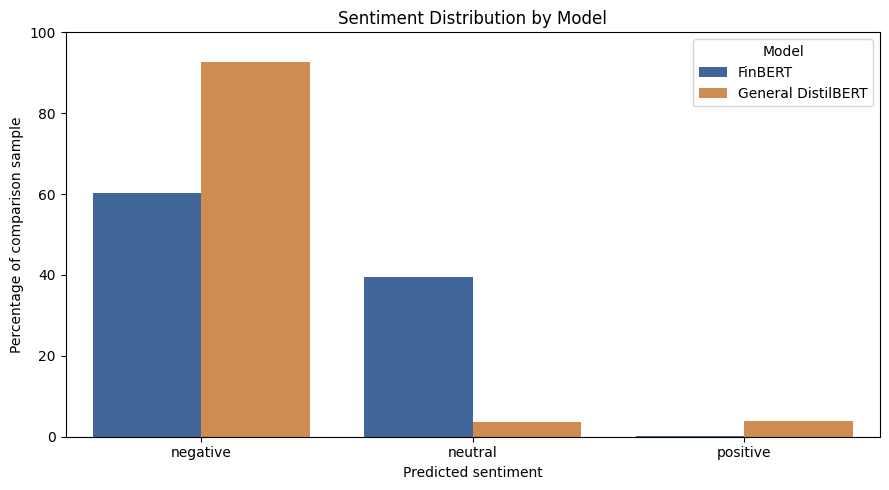

In [18]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=distribution_comparison,
    x="sentiment",
    y="percentage",
    hue="model",
    order=SENTIMENT_LABELS,
    palette=["#3264A8", "#E38B3B"]
)

plt.title("Sentiment Distribution by Model")
plt.xlabel("Predicted sentiment")
plt.ylabel("Percentage of comparison sample")
plt.ylim(0, 100)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

In [19]:
confidence_comparison = pd.DataFrame({
    "FinBERT": comparison_sample["finbert_confidence"],
    "General DistilBERT":
        comparison_sample["general_distilbert_confidence"]
}).agg([
    "mean",
    "median",
    "std",
    "min",
    "max"
]).T.round(4)

display(confidence_comparison)

,mean,median,std,min,max
FinBERT,0.7556,0.773,0.1452,0.4769,0.9550
General DistilBERT,0.6562,0.647,0.1510,0.3454,0.9429


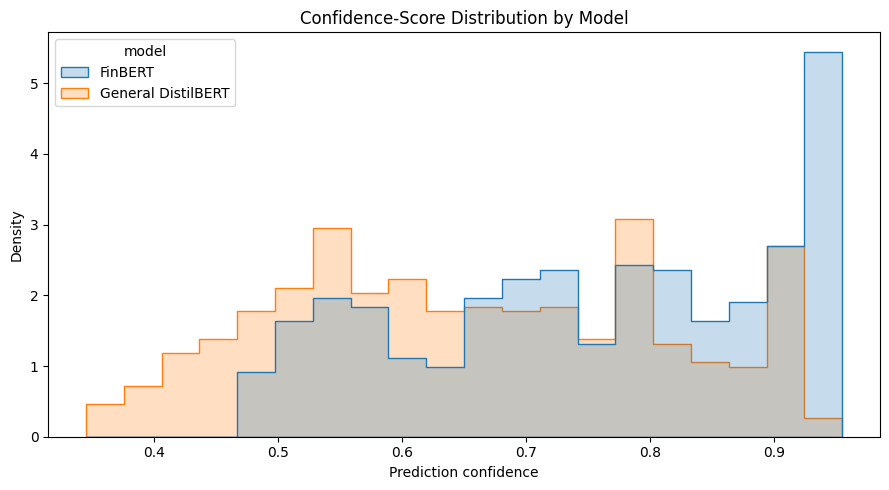

In [20]:
confidence_long = comparison_sample[
    [
        "finbert_confidence",
        "general_distilbert_confidence"
    ]
].rename(columns={
    "finbert_confidence": "FinBERT",
    "general_distilbert_confidence": "General DistilBERT"
}).melt(
    var_name="model",
    value_name="confidence"
)

plt.figure(figsize=(9, 5))

sns.histplot(
    data=confidence_long,
    x="confidence",
    hue="model",
    bins=20,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Confidence-Score Distribution by Model")
plt.xlabel("Prediction confidence")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

## 8. Model Agreement and Disagreement

Agreement analysis measures how consistently the two pretrained models interpret the same narratives.

The analysis includes:

- overall agreement rate;
- cross-tabulation of model predictions;
- most frequent disagreement combinations;
- average confidence within each disagreement type.

Agreement does not establish correctness. However, substantial disagreement can reveal differences caused by the models' training domains and treatment of complaint language.

In [21]:
comparison_sample["models_agree"] = (
    comparison_sample["finbert_label"]
    == comparison_sample["general_distilbert_label"]
)

agreement_count = comparison_sample["models_agree"].sum()
disagreement_count = (~comparison_sample["models_agree"]).sum()
agreement_rate = comparison_sample["models_agree"].mean() * 100

agreement_summary = pd.DataFrame({
    "measure": [
        "Model agreements",
        "Model disagreements",
        "Agreement rate (%)"
    ],
    "value": [
        agreement_count,
        disagreement_count,
        round(agreement_rate, 2)
    ]
})

display(agreement_summary)

,measure,value
0,Model agreements,311.0
1,Model disagreements,189.0
2,Agreement rate (%),62.2


In [22]:
agreement_matrix = pd.crosstab(
    comparison_sample["finbert_label"],
    comparison_sample["general_distilbert_label"],
    rownames=["FinBERT"],
    colnames=["General DistilBERT"]
).reindex(
    index=SENTIMENT_LABELS,
    columns=SENTIMENT_LABELS,
    fill_value=0
)

display(agreement_matrix)

General DistilBERT,negative,neutral,positive
FinBERT,,,
negative,294,2,5
neutral,169,16,13
positive,0,0,1


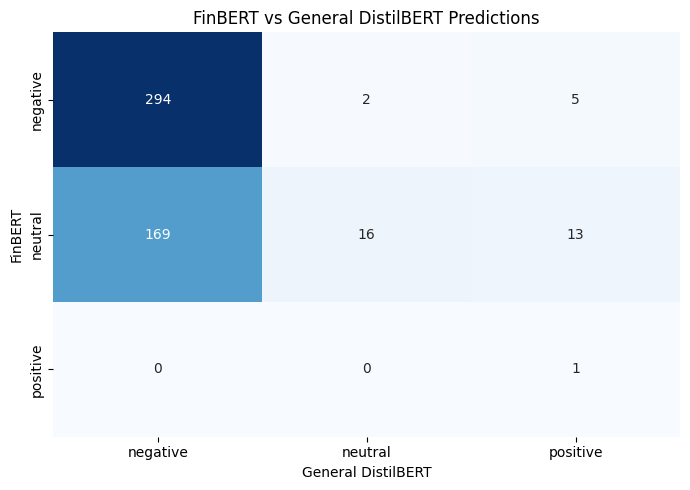

In [23]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    agreement_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False
)

plt.title("FinBERT vs General DistilBERT Predictions")
plt.xlabel("General DistilBERT")
plt.ylabel("FinBERT")
plt.tight_layout()
plt.show()

In [24]:
disagreement_cases = comparison_sample.loc[
    ~comparison_sample["models_agree"]
].copy()

disagreement_summary = (
    disagreement_cases
    .groupby(
        [
            "finbert_label",
            "general_distilbert_label"
        ]
    )
    .agg(
        narratives=(ID_COL, "size"),
        mean_finbert_confidence=(
            "finbert_confidence",
            "mean"
        ),
        mean_general_confidence=(
            "general_distilbert_confidence",
            "mean"
        )
    )
    .reset_index()
    .sort_values(
        "narratives",
        ascending=False
    )
)

disagreement_summary[
    [
        "mean_finbert_confidence",
        "mean_general_confidence"
    ]
] = disagreement_summary[
    [
        "mean_finbert_confidence",
        "mean_general_confidence"
    ]
].round(4)

display(disagreement_summary)

,finbert_label,general_distilbert_label,narratives,mean_finbert_confidence,mean_general_confidence
2,neutral,negative,169,0.7073,0.5705
3,neutral,positive,13,0.8305,0.4515
1,negative,positive,5,0.7721,0.4470
0,negative,neutral,2,0.6604,0.5132


## 9. Qualitative Inspection of Model Predictions

A small number of agreement and disagreement cases are displayed to understand how the models interpret consumer complaint language.

This is not a manual-labelling exercise. No reference labels are created, and the examples are not used to calculate model accuracy.

The inspection focuses on:

- confident cases where both models agree;
- confident cases where the models disagree;
- whether factual descriptions of harmful events are interpreted as neutral or negative;
- possible effects of the models' different training domains.

In [25]:
comparison_sample["combined_confidence"] = (
    comparison_sample["finbert_confidence"]
    + comparison_sample["general_distilbert_confidence"]
) / 2

comparison_sample["comparison_case"] = np.where(
    comparison_sample["models_agree"],
    "Agreement: " + comparison_sample["finbert_label"],
    (
        "Disagreement: FinBERT="
        + comparison_sample["finbert_label"]
        + " | General="
        + comparison_sample["general_distilbert_label"]
    )
)

# Two confident examples from each disagreement combination
disagreement_examples = (
    comparison_sample.loc[
        ~comparison_sample["models_agree"]
    ]
    .sort_values(
        "combined_confidence",
        ascending=False
    )
    .groupby(
        [
            "finbert_label",
            "general_distilbert_label"
        ],
        group_keys=False
    )
    .head(2)
)

# One confident agreement example from each available sentiment
agreement_examples = (
    comparison_sample.loc[
        comparison_sample["models_agree"]
    ]
    .sort_values(
        "combined_confidence",
        ascending=False
    )
    .groupby(
        "finbert_label",
        group_keys=False
    )
    .head(1)
)

qualitative_sample = pd.concat(
    [
        disagreement_examples,
        agreement_examples
    ],
    ignore_index=True
)

qualitative_sample["narrative_preview"] = (
    qualitative_sample[TEXT_COL]
    .str.slice(0, 500)
)

qualitative_sample = qualitative_sample[
    [
        ID_COL,
        PRODUCT_COL,
        "comparison_case",
        "finbert_confidence",
        "general_distilbert_confidence",
        "narrative_preview"
    ]
].copy()

qualitative_sample[
    [
        "finbert_confidence",
        "general_distilbert_confidence"
    ]
] = qualitative_sample[
    [
        "finbert_confidence",
        "general_distilbert_confidence"
    ]
].round(3)

pd.set_option("display.max_colwidth", 500)

display(qualitative_sample)

,complaint_id,product,comparison_case,finbert_confidence,general_distilbert_confidence,narrative_preview
0,15221815,Mortgage,Disagreement: FinBERT=neutral | General=negative,0.860,0.793,"I'm a XXXX veteran and have a VA mortgage loan on XX/XX/XXXX. I spoke to XXXX @ XXXX to apply for a loan modification. Due to a loss of income, things got tough and were looking to tack XXXX, XXXX, and XXXX mortgages at the end of the mortgage loan term and would have an answer in 30 days. My mortgage was originally with XXXX XXXX, they sold it to XXXX, which in turn sold it to M & T Bank. I applied for a loan modification with M & T Bank, and recently learned I was denied, in the mortgage a..."
1,18262241,Debt collection,Disagreement: FinBERT=neutral | General=negative,0.910,0.741,"To Whom This May Concern, I have received information regarding a debt that is being claimed against me. Through my rights, in accordance with 15 U.S. Code 1692g, I hold the right to verify the total debt amount, including any fees, and who the original party that is making the claim. After receiving such information, I will review and respond within the XXXX period allotted to me under federal law. If it is found that there is no evidence of this debt under my name, then I demand that all c..."
2,13479217,Checking or savings account,Disagreement: FinBERT=neutral | General=positive,0.888,0.610,"On XX/XX/year>2025 The bank chase XXXX my bank account, In which I had a positive balance XXXX, I when calling customer service and asking what happened to my money, They tell me that I will be sent a check with the amount of money that I had available there in an average of 10 working days, I have called customer service on many occasions and nobody gives me a clear answer why the check has not reached me or where my funds are, please help me"
3,18228063,Checking or savings account,Disagreement: FinBERT=neutral | General=positive,0.946,0.528,"XX/XX/year>, copy of Certificate of Deposit ( CD ), {$15000.00}, with my name as Personal Representative named for a parent..."
4,12857605,Checking or savings account,Disagreement: FinBERT=negative | General=neutral,0.832,0.526,"5 charges each appeared on two business checking accounts with Chase, for a total of {$320.00} with a label of "" ACCOUNT ANALYSIS SETTLEMENT CHARGE '' starting in XX/XX/XXXX, one per month. I noticed the charges in XXXX of XXXX and contacted Chase by email and phone. After just over 2 months of slow communication, my banker, a XXXX in the XXXX XXXX group, agreed by phone to remove the charges as they were due to an account setup error related to the XXXX XXXX account conversion. This was 7 b..."
5,18248911,Credit card,Disagreement: FinBERT=negative | General=positive,0.927,0.430,"Capital One 's online transactions page shows my payment of {$320.00} XX/XX/XXXX. See attached. Today, XX/XX/year>, Capitol One has reported me as being 30 days late on my payment with the credit bureaus."
6,13348021,Credit card,Disagreement: FinBERT=negative | General=positive,0.937,0.394,"I have been unable to access my Citi credit card online account ( both desktop and mobile ) for several months. Despite multiple calls and attempts to resolve the issue through Citi customer service, the problem remains unresolved. As a result, I can not view transaction details or redeem my reward points. I believe my account is in good standing, and I have provided all necessary verification during previous support calls. This ongoing issue has caused significant inconvenience and raises c..."
7,12124201,"Money transfer, virtual currency, or money service",Disagreement: FinBERT=negative | General=neutral,0.489,0.500,Cash app closed my account and took my money with no explanation I couldnt speak to a live representative
8,11604765,"Money transfer, virtual currency, or money service",Agreement: negative,0.955,0.926,"I am filling a complaint with cash app due to inadequate customer service and unfair practices, which indeed violate the Customer Ser

## 10. Final Model Selection

### Selected model: FinBERT

FinBERT is selected for the final sentiment analysis.

The decision is based on the following evidence:

1. **Domain suitability**

   FinBERT was trained on financial language, making its vocabulary and contextual representations more relevant to banking, debt, mortgage and payment complaints.

2. **Prediction distribution**

   FinBERT produced a more differentiated distribution:

   - 60.2% negative
   - 39.6% neutral
   - 0.2% positive

   General DistilBERT classified 92.6% of the sample as negative, suggesting a strong tendency to interpret nearly all complaint language as negative.

3. **Confidence**

   FinBERT had a higher mean confidence score of 0.7556, compared with 0.6562 for General DistilBERT.

4. **Agreement analysis**

   The models agreed on 62.2% of narratives. Most disagreements occurred when FinBERT predicted neutral and General DistilBERT predicted negative.

5. **Qualitative inspection**

   General DistilBERT occasionally classified clearly adverse situations—such as missing funds, incorrect late-payment reporting and unresolved account-access problems—as positive.

   FinBERT generally produced more contextually reasonable predictions for these financially specific complaints.

### Limitation

FinBERT is not specifically trained on CFPB consumer complaints and is not assumed to be perfectly accurate. Its predictions are used as model-generated indicators for exploratory complaint analysis.

In [26]:
SELECTED_MODEL_KEY = "finbert"
SELECTED_MODEL_NAME = MODEL_SPECS[
    SELECTED_MODEL_KEY
]["model_name"]

print("Selected model:", SELECTED_MODEL_NAME)
print("Final inference dataset:", full_narratives.shape)

Selected model: ProsusAI/finbert
Final inference dataset: (272466, 3)


## 11. Full-Dataset Sentiment Inference

The selected FinBERT model is now applied to all 272,466 complaint narratives.

The inference process:

- uses the prepared narrative text without additional cleaning;
- divides long narratives into overlapping token chunks;
- aggregates chunk probabilities into one prediction per complaint;
- processes the dataset in memory-safe blocks;
- saves progress after every block;
- can resume from the latest completed checkpoint.

This full dataset is used to calculate real sentiment volumes.

In [ ]:
# OUTPUT_DIR = Path("notebook6_outputs")
# OUTPUT_DIR.mkdir(exist_ok=True)

# FULL_PREDICTIONS_PATH = (
#     OUTPUT_DIR / "finbert_full_predictions.csv"
# )

# BLOCK_SIZE = 5000
# INFERENCE_BATCH_SIZE = 16

# print("Checkpoint:", FULL_PREDICTIONS_PATH)
# print("Block size:", BLOCK_SIZE)
# print("Inference batch size:", INFERENCE_BATCH_SIZE)

Checkpoint: notebook6_outputs/finbert_full_predictions.csv
Block size: 5000
Inference batch size: 16


In [ ]:
# def predict_block_with_loaded_model(
#     dataframe,
#     tokenizer,
#     model,
#     raw_labels,
#     batch_size=16
# ):
#     reorder_indices = [
#         raw_labels.index(label)
#         for label in SENTIMENT_LABELS
#     ]
    
#     encoded_chunks = []
#     complaint_positions = []
#     chunk_weights = []
#     chunks_per_complaint = []
    
#     for position, text in enumerate(dataframe[TEXT_COL]):
#         chunks = create_token_chunks(text, tokenizer)
#         chunks_per_complaint.append(len(chunks))
        
#         for chunk in chunks:
#             encoded = tokenizer.prepare_for_model(
#                 chunk,
#                 add_special_tokens=True,
#                 return_attention_mask=True,
#                 truncation=True,
#                 max_length=512
#             )
            
#             encoded_chunks.append(encoded)
#             complaint_positions.append(position)
#             chunk_weights.append(max(len(chunk), 1))
    
#     probability_batches = []
    
#     for start in range(
#         0,
#         len(encoded_chunks),
#         batch_size
#     ):
#         batch_chunks = encoded_chunks[
#             start:start + batch_size
#         ]
        
#         batch = tokenizer.pad(
#             batch_chunks,
#             padding=True,
#             return_tensors="pt"
#         )
        
#         batch = {
#             key: value.to(DEVICE)
#             for key, value in batch.items()
#         }
        
#         with torch.inference_mode():
#             logits = model(**batch).logits
#             probabilities = torch.softmax(
#                 logits,
#                 dim=-1
#             )
        
#         probabilities = (
#             probabilities[:, reorder_indices]
#             .detach()
#             .cpu()
#             .numpy()
#         )
        
#         probability_batches.append(probabilities)
    
#     all_probabilities = np.vstack(
#         probability_batches
#     )
    
#     complaint_positions = np.asarray(
#         complaint_positions
#     )
    
#     chunk_weights = np.asarray(
#         chunk_weights,
#         dtype=np.float32
#     )
    
#     weighted_probability_sums = np.zeros(
#         (len(dataframe), 3),
#         dtype=np.float32
#     )
    
#     total_weights = np.zeros(
#         len(dataframe),
#         dtype=np.float32
#     )
    
#     np.add.at(
#         weighted_probability_sums,
#         complaint_positions,
#         all_probabilities * chunk_weights[:, None]
#     )
    
#     np.add.at(
#         total_weights,
#         complaint_positions,
#         chunk_weights
#     )
    
#     complaint_probabilities = (
#         weighted_probability_sums
#         / total_weights[:, None]
#     )
    
#     predicted_indices = complaint_probabilities.argmax(
#         axis=1
#     )
    
#     return pd.DataFrame({
#         ID_COL: dataframe[ID_COL].astype("string").values,
#         PRODUCT_COL: dataframe[PRODUCT_COL].values,
#         "sentiment_label": [
#             SENTIMENT_LABELS[index]
#             for index in predicted_indices
#         ],
#         "negative_probability":
#             complaint_probabilities[:, 0],
#         "neutral_probability":
#             complaint_probabilities[:, 1],
#         "positive_probability":
#             complaint_probabilities[:, 2],
#         "sentiment_confidence":
#             complaint_probabilities.max(axis=1),
#         "sentiment_chunk_count":
#             chunks_per_complaint
#     })

In [30]:
# # Determine whether a valid checkpoint already exists
# completed_rows = 0

# if FULL_PREDICTIONS_PATH.exists():
#     existing_checkpoint = pd.read_csv(
#         FULL_PREDICTIONS_PATH,
#         dtype={ID_COL: "string"}
#     )
    
#     completed_rows = len(existing_checkpoint)
    
#     if completed_rows > len(full_narratives):
#         raise ValueError(
#             "Checkpoint contains more rows than the source dataset."
#         )
    
#     expected_ids = (
#         full_narratives[ID_COL]
#         .iloc[:completed_rows]
#         .astype("string")
#         .reset_index(drop=True)
#     )
    
#     saved_ids = (
#         existing_checkpoint[ID_COL]
#         .astype("string")
#         .reset_index(drop=True)
#     )
    
#     if not saved_ids.equals(expected_ids):
#         raise ValueError(
#             "Checkpoint complaint IDs do not match the "
#             "current dataset order."
#         )
    
#     del existing_checkpoint
    
#     print(
#         f"Valid checkpoint found: "
#         f"{completed_rows:,} completed rows."
#     )
# else:
#     print("No checkpoint found. Starting from row 0.")


# if completed_rows < len(full_narratives):
#     tokenizer = AutoTokenizer.from_pretrained(
#         SELECTED_MODEL_NAME
#     )
    
#     model = AutoModelForSequenceClassification.from_pretrained(
#         SELECTED_MODEL_NAME
#     )
    
#     model.to(DEVICE)
#     model.eval()
    
#     raw_labels = [
#         str(model.config.id2label[i]).lower()
#         for i in range(model.config.num_labels)
#     ]
    
#     print("Model label order:", raw_labels)
#     print("Running on:", DEVICE)
    
#     inference_start = time.time()
    
#     for block_start in tqdm(
#         range(
#             completed_rows,
#             len(full_narratives),
#             BLOCK_SIZE
#         ),
#         desc="Full FinBERT inference"
#     ):
#         block_end = min(
#             block_start + BLOCK_SIZE,
#             len(full_narratives)
#         )
        
#         data_block = (
#             full_narratives
#             .iloc[block_start:block_end]
#             .reset_index(drop=True)
#         )
        
#         block_predictions = predict_block_with_loaded_model(
#             dataframe=data_block,
#             tokenizer=tokenizer,
#             model=model,
#             raw_labels=raw_labels,
#             batch_size=INFERENCE_BATCH_SIZE
#         )
        
#         write_header = not FULL_PREDICTIONS_PATH.exists()
        
#         block_predictions.to_csv(
#             FULL_PREDICTIONS_PATH,
#             mode="a",
#             header=write_header,
#             index=False
#         )
        
#         print(
#             f"Saved rows {block_start:,}–"
#             f"{block_end - 1:,}"
#         )
        
#         if DEVICE.type == "mps":
#             torch.mps.empty_cache()
    
#     elapsed_hours = (
#         time.time() - inference_start
#     ) / 3600
    
#     print(
#         f"\nInference completed in "
#         f"{elapsed_hours:.2f} hours."
#     )
    
#     model.to("cpu")
#     del model, tokenizer
    
#     if DEVICE.type == "mps":
#         torch.mps.empty_cache()

# else:
#     print("Full inference was already completed.")

In [36]:
# full_sentiment_predictions = pd.read_csv(
#     FULL_PREDICTIONS_PATH,
#     dtype={ID_COL: "string"}
# )

# print(
#     "Saved prediction dataset:",
#     full_sentiment_predictions.shape
# )

# print(
#     "Expected rows:",
#     len(full_narratives)
# )

# print(
#     "Duplicate complaint IDs:",
#     full_sentiment_predictions[ID_COL]
#     .duplicated()
#     .sum()
# )

# print(
#     "Missing sentiment labels:",
#     full_sentiment_predictions["sentiment_label"]
#     .isna()
#     .sum()
# )

In [40]:
from pathlib import Path
import pandas as pd

ID_COL = "complaint_id"

# FULL_DATA_PATH = Path("full_narratives_prepared.csv")
# SENTIMENT_PATH = Path("finbert_full_predictions.csv.gz")



FULL_DATA_PATH = Path(
    "/Users/ishika/Documents/AIProject/data/processed/"
    "full_narratives_prepared.csv"
)

SENTIMENT_PATH = Path(
    "/Users/ishika/Documents/AIProject/data/processed/"
    "finbert_full_predictions.csv.gz"
)

full_metadata = pd.read_csv(
    FULL_DATA_PATH,
    low_memory=False
)

sentiment_predictions = pd.read_csv(
    SENTIMENT_PATH,
    compression="gzip",
    low_memory=False
)

# Ensure matching ID types
full_metadata[ID_COL] = full_metadata[ID_COL].astype("string")
sentiment_predictions[ID_COL] = (
    sentiment_predictions[ID_COL].astype("string")
)

sentiment_columns = [
    ID_COL,
    "sentiment_label",
    "negative_probability",
    "neutral_probability",
    "positive_probability",
    "sentiment_confidence",
    "sentiment_chunk_count"
]

sentiment_enriched = full_metadata.merge(
    sentiment_predictions[sentiment_columns],
    on=ID_COL,
    how="left",
    validate="one_to_one"
)

merge_checks = pd.DataFrame({
    "check": [
        "Original narrative rows",
        "Prediction rows",
        "Merged rows",
        "Missing sentiment labels",
        "Duplicate complaint IDs",
        "Final columns"
    ],
    "value": [
        len(full_metadata),
        len(sentiment_predictions),
        len(sentiment_enriched),
        sentiment_enriched["sentiment_label"].isna().sum(),
        sentiment_enriched[ID_COL].duplicated().sum(),
        sentiment_enriched.shape[1]
    ]
})

display(merge_checks)

,check,value
0,Original narrative rows,272466
1,Prediction rows,272466
2,Merged rows,272466
3,Missing sentiment labels,0
4,Duplicate complaint IDs,0
5,Final columns,43


In [41]:
relevant_columns = [
    column for column in sentiment_enriched.columns
    if any(
        keyword in column.lower()
        for keyword in [
            "company",
            "issue",
            "response",
            "timely"
        ]
    )
]

print(relevant_columns)

['issue', 'sub_issue', 'company_public_response', 'company', 'date_sent_to_company', 'company_response_to_consumer', 'timely_response', 'sub_issue_available', 'issue_detail', 'issue_theme']


## 15. Company-Level Sentiment Analysis

Company-level analysis examines both complaint volume and the proportion of narratives classified as negative.

To avoid unstable rankings based on very small samples, negative-sentiment comparisons are limited to companies with at least 500 narrative complaints. These results represent model-generated exploratory indicators, not verified company-performance scores.

In [42]:
MIN_COMPANY_COMPLAINTS = 500

company_summary = (
    sentiment_enriched
    .dropna(subset=["company"])
    .groupby("company")
    .agg(
        total_complaints=(ID_COL, "size"),
        negative_complaints=(
            "sentiment_label",
            lambda values: (values == "negative").sum()
        ),
        neutral_complaints=(
            "sentiment_label",
            lambda values: (values == "neutral").sum()
        ),
        positive_complaints=(
            "sentiment_label",
            lambda values: (values == "positive").sum()
        ),
        mean_negative_probability=(
            "negative_probability",
            "mean"
        ),
        mean_confidence=(
            "sentiment_confidence",
            "mean"
        )
    )
    .reset_index()
)

company_summary["negative_percentage"] = (
    company_summary["negative_complaints"]
    / company_summary["total_complaints"]
    * 100
).round(2)

company_summary["mean_negative_probability"] = (
    company_summary["mean_negative_probability"].round(4)
)

company_summary["mean_confidence"] = (
    company_summary["mean_confidence"].round(4)
)

largest_companies = (
    company_summary
    .sort_values("total_complaints", ascending=False)
    .head(15)
)

highest_negative_companies = (
    company_summary[
        company_summary["total_complaints"]
        >= MIN_COMPANY_COMPLAINTS
    ]
    .sort_values(
        ["negative_percentage", "total_complaints"],
        ascending=[False, False]
    )
    .head(15)
)

print("Largest companies by narrative complaint volume")
display(largest_companies)

print(
    "Highest negative percentages "
    f"(minimum {MIN_COMPANY_COMPLAINTS} complaints)"
)
display(highest_negative_companies)

Largest companies by narrative complaint volume


,company,total_complaints,negative_complaints,neutral_complaints,positive_complaints,mean_negative_probability,mean_confidence,negative_percentage
378,"Block, Inc.",37204,32457,4744,3,0.8262,0.8830,87.24
873,"Early Warning Services, LLC",16786,15044,1740,2,0.8370,0.8876,89.62
429,CAPITAL ONE FINANCIAL CORPORATION,12626,6814,5807,5,0.5255,0.7097,53.97
860,"EQUIFAX, INC.",11082,4148,6205,729,0.4399,0.6678,37.43
2352,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",10107,3891,5456,760,0.4356,0.6757,38.50
1272,JPMORGAN CHASE & CO.,10054,5008,5039,7,0.4814,0.6974,49.81
1640,NAVY FEDERAL CREDIT UNION,9395,7623,1769,3,0.7511,0.8399,81.14
912,Experian Information Solutions Inc.,8935,3478,4965,492,0.4470,0.6766,38.93
2572,WELLS FARGO & COMPANY,7605,3636,3963,6,0.4728,0.6958,47.81
469,"CITIBANK, N.A.",7550,3915,3632,3,0.4921,0.6985,51.85


Highest negative percentages (minimum 500 complaints)


,company,total_complaints,negative_complaints,neutral_complaints,positive_complaints,mean_negative_probability,mean_confidence,negative_percentage
873,"Early Warning Services, LLC",16786,15044,1740,2,0.8370,0.8876,89.62
378,"Block, Inc.",37204,32457,4744,3,0.8262,0.8830,87.24
1640,NAVY FEDERAL CREDIT UNION,9395,7623,1769,3,0.7511,0.8399,81.14
1877,"Paypal Holdings, Inc",4614,2717,1897,0,0.5325,0.6912,58.89
2323,T.S. Holdings,821,463,358,0,0.5128,0.7193,56.39
592,Chime Financial Inc,5314,2943,2371,0,0.5252,0.7039,55.38
2139,"SOFI TECHNOLOGIES, INC.",1512,837,674,1,0.5218,0.6956,55.36
1063,GOLDMAN SACHS BANK USA,1817,1001,815,1,0.5116,0.6972,55.09
327,BMO BANK NATIONAL ASSOCIATION,590,323,267,0,0.5101,0.7066,54.75
1832,PNC Bank N.A.,1413,773,640,0,0.5049,0.7034,54.71


### Company-Level Interpretation

Among companies with at least 500 narrative complaints, Early Warning Services has the highest negative classification rate at 89.62%, followed by Block at 87.24% and Navy Federal Credit Union at 81.14%.

Block also has the largest narrative complaint volume, with 37,204 complaints, of which 32,457 were classified as negative. This combination of high volume and high negative concentration makes it particularly notable for later risk-indicator development.

However, these percentages are influenced by each company's product mix. For example, Early Warning Services and Block are strongly associated with money-transfer services, which had the highest overall negative sentiment rate. Consequently, these results should not be interpreted as direct rankings of company performance.

The relatively large number of positive predictions for credit-reporting companies may reflect formal or template-based complaint language rather than genuine customer satisfaction. Company-level results remain exploratory because no human-labelled reference data are available.

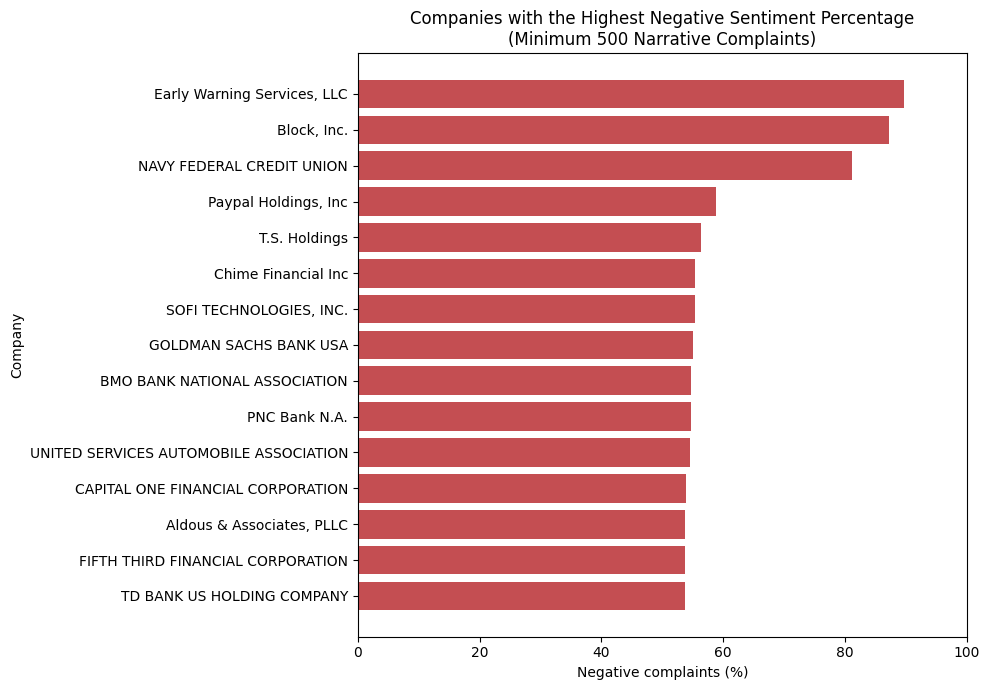

In [43]:
company_plot = (
    highest_negative_companies
    .sort_values("negative_percentage", ascending=True)
)

plt.figure(figsize=(10, 7))

plt.barh(
    company_plot["company"],
    company_plot["negative_percentage"],
    color="#C44E52"
)

plt.title(
    "Companies with the Highest Negative Sentiment Percentage\n"
    f"(Minimum {MIN_COMPANY_COMPLAINTS} Narrative Complaints)"
)
plt.xlabel("Negative complaints (%)")
plt.ylabel("Company")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

## 16. Issue-Level Sentiment Analysis

Issue-level analysis identifies complaint categories associated with both high narrative volume and high concentrations of negative sentiment.

A minimum of 500 narrative complaints is applied when ranking issues by negative percentage. This reduces the influence of categories containing only a small number of observations.

In [44]:
MIN_ISSUE_COMPLAINTS = 500

issue_summary = (
    sentiment_enriched
    .dropna(subset=["issue"])
    .groupby("issue")
    .agg(
        total_complaints=(ID_COL, "size"),
        negative_complaints=(
            "sentiment_label",
            lambda values: (values == "negative").sum()
        ),
        neutral_complaints=(
            "sentiment_label",
            lambda values: (values == "neutral").sum()
        ),
        positive_complaints=(
            "sentiment_label",
            lambda values: (values == "positive").sum()
        ),
        mean_negative_probability=(
            "negative_probability",
            "mean"
        ),
        mean_confidence=(
            "sentiment_confidence",
            "mean"
        )
    )
    .reset_index()
)

issue_summary["negative_percentage"] = (
    issue_summary["negative_complaints"]
    / issue_summary["total_complaints"]
    * 100
).round(2)

issue_summary["mean_negative_probability"] = (
    issue_summary["mean_negative_probability"].round(4)
)

issue_summary["mean_confidence"] = (
    issue_summary["mean_confidence"].round(4)
)

largest_issues = (
    issue_summary
    .sort_values("total_complaints", ascending=False)
    .head(15)
)

highest_negative_issues = (
    issue_summary[
        issue_summary["total_complaints"]
        >= MIN_ISSUE_COMPLAINTS
    ]
    .sort_values(
        ["negative_percentage", "total_complaints"],
        ascending=[False, False]
    )
    .head(15)
)

print("Largest issues by narrative complaint volume")
display(largest_issues)

print(
    "Issues with the highest negative percentages "
    f"(minimum {MIN_ISSUE_COMPLAINTS} complaints)"
)
display(highest_negative_issues)

Largest issues by narrative complaint volume


,issue,total_complaints,negative_complaints,neutral_complaints,positive_complaints,mean_negative_probability,mean_confidence,negative_percentage
2,Attempts to collect debt not owed,45772,20608,23182,1982,0.4492,0.7065,45.02
25,Other transaction problem,45406,42750,2653,3,0.8863,0.9140,94.15
19,Managing an account,26503,14213,12285,5,0.5157,0.6957,53.63
45,Written notification about debt,24188,7791,16395,2,0.4000,0.7005,32.21
11,False statements or representation,14034,4848,9176,10,0.3680,0.7555,34.54
32,Problem with a purchase shown on your statement,11102,6166,4933,3,0.5172,0.6783,55.54
28,Problem caused by your funds being low,9338,7780,1551,7,0.7643,0.8438,83.32
38,Took or threatened to take negative or legal action,8033,4551,3480,2,0.5214,0.7241,56.65
40,Trouble during payment process,7352,3761,3577,14,0.4903,0.7041,51.16
13,Fraud or scam,6897,3117,3779,1,0.4611,0.6918,45.19


Issues with the highest negative percentages (minimum 500 complaints)


,issue,total_complaints,negative_complaints,neutral_complaints,positive_complaints,mean_negative_probability,mean_confidence,negative_percentage
25,Other transaction problem,45406,42750,2653,3,0.8863,0.9140,94.15
28,Problem caused by your funds being low,9338,7780,1551,7,0.7643,0.8438,83.32
24,Other service problem,1522,1205,317,0,0.7463,0.8456,79.17
30,Problem with a company's investigation into an existing problem,2353,1703,650,0,0.5945,0.7050,72.38
36,Struggling to pay your bill,593,416,175,2,0.6101,0.7375,70.15
41,Trouble using your card,1875,1246,621,8,0.5961,0.7304,66.45
5,Closing your account,3543,2307,1230,6,0.5802,0.7236,65.11
29,Problem when making payments,2428,1471,956,1,0.5414,0.7013,60.58
20,"Managing, opening, or closing your mobile wallet account",978,583,395,0,0.5367,0.7051,59.61
39,Trouble accessing funds in your mobile or digital wallet,2041,1199,842,0,0.5317,0.7047,58.75


### Issue-Level Interpretation

“Other transaction problem” is the most prominent sentiment risk category. It contains 45,406 narrative complaints, of which 94.15% were classified as negative. It therefore combines exceptionally high negative concentration with substantial complaint volume.

“Problem caused by your funds being low” also shows a high negative rate of 83.32%, followed by “Other service problem” at 79.17%.

By contrast, several debt-collection issues contain larger neutral proportions. For example, “Written notification about debt” has a negative rate of 32.21%. This may reflect the formal and template-based language commonly used in debt-validation narratives rather than an absence of adverse consumer experiences.

Broad categories beginning with “Other” offer limited operational detail. Topic modelling in Notebook 7 will help identify more specific themes within these narratives. All issue-level sentiment findings remain exploratory model outputs.

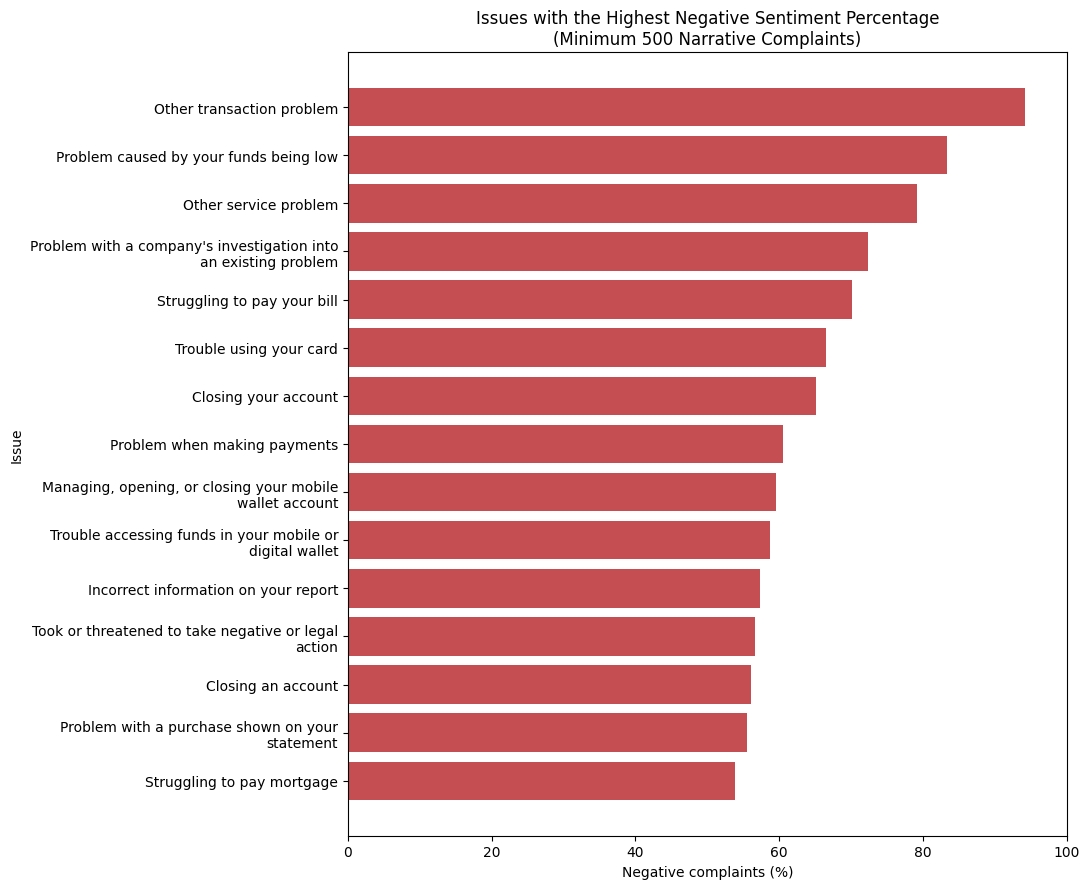

In [45]:
import textwrap

issue_plot = (
    highest_negative_issues
    .sort_values("negative_percentage", ascending=True)
    .copy()
)

issue_plot["wrapped_issue"] = issue_plot["issue"].apply(
    lambda value: "\n".join(
        textwrap.wrap(value, width=45)
    )
)

plt.figure(figsize=(11, 9))

plt.barh(
    issue_plot["wrapped_issue"],
    issue_plot["negative_percentage"],
    color="#C44E52"
)

plt.title(
    "Issues with the Highest Negative Sentiment Percentage\n"
    f"(Minimum {MIN_ISSUE_COMPLAINTS} Narrative Complaints)"
)
plt.xlabel("Negative complaints (%)")
plt.ylabel("Issue")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

## 17. Sentiment Across Company Response Outcomes

This section compares model-generated sentiment across company response categories and timely-response status.

Consumer narratives are submitted before companies provide their recorded responses. Therefore, differences observed here represent associations between complaint sentiment and eventual response outcomes, not causal effects of those responses.

In [46]:
def create_response_summary(dataframe, group_column):
    summary = (
        dataframe
        .dropna(subset=[group_column])
        .groupby(group_column)
        .agg(
            total_complaints=(ID_COL, "size"),
            negative_complaints=(
                "sentiment_label",
                lambda values: (values == "negative").sum()
            ),
            neutral_complaints=(
                "sentiment_label",
                lambda values: (values == "neutral").sum()
            ),
            positive_complaints=(
                "sentiment_label",
                lambda values: (values == "positive").sum()
            ),
            mean_negative_probability=(
                "negative_probability",
                "mean"
            ),
            mean_confidence=(
                "sentiment_confidence",
                "mean"
            )
        )
        .reset_index()
    )

    summary["negative_percentage"] = (
        summary["negative_complaints"]
        / summary["total_complaints"]
        * 100
    ).round(2)

    summary["mean_negative_probability"] = (
        summary["mean_negative_probability"].round(4)
    )

    summary["mean_confidence"] = (
        summary["mean_confidence"].round(4)
    )

    return summary.sort_values(
        "total_complaints",
        ascending=False
    )


response_outcome_summary = create_response_summary(
    sentiment_enriched,
    "company_response_to_consumer"
)

timeliness_summary = create_response_summary(
    sentiment_enriched,
    "timely_response"
)

print("Sentiment by company response to consumer")
display(response_outcome_summary)

print("Sentiment by timely-response status")
display(timeliness_summary)

Sentiment by company response to consumer


,company_response_to_consumer,total_complaints,negative_complaints,neutral_complaints,positive_complaints,mean_negative_probability,mean_confidence,negative_percentage
0,Closed with explanation,223508,131960,90475,1073,0.5696,0.7570,59.04
2,Closed with non-monetary relief,34251,14858,18391,1002,0.4471,0.7050,43.38
1,Closed with monetary relief,13620,7094,6524,2,0.4987,0.6893,52.09
4,Untimely response,1081,538,543,0,0.4658,0.7188,49.77
3,In progress,6,3,3,0,0.6229,0.7001,50.00


Sentiment by timely-response status


,timely_response,total_complaints,negative_complaints,neutral_complaints,positive_complaints,mean_negative_probability,mean_confidence,negative_percentage
1,Yes,268233,152396,113760,2077,0.5516,0.7474,56.81
0,No,4233,2057,2176,0,0.4652,0.7190,48.59


### Response-Outcome Interpretation

Complaints eventually closed with an explanation have the highest negative classification rate at 59.04%. Complaints receiving monetary relief have a negative rate of 52.09%, while those receiving non-monetary relief have the lowest rate at 43.38%.

Timely-response complaints have a negative rate of 56.81%, compared with approximately 48.59% for complaints marked as not timely. This does not mean timely responses produce more negative sentiment. The consumer narrative was submitted before the company response, and the groups may contain different products, companies and complaint issues.

Only six narrative complaints remain in progress, so this category is too small to support a meaningful comparison.

These results show associations between initial complaint sentiment and eventual response outcomes, not causal effects or measures of response effectiveness.

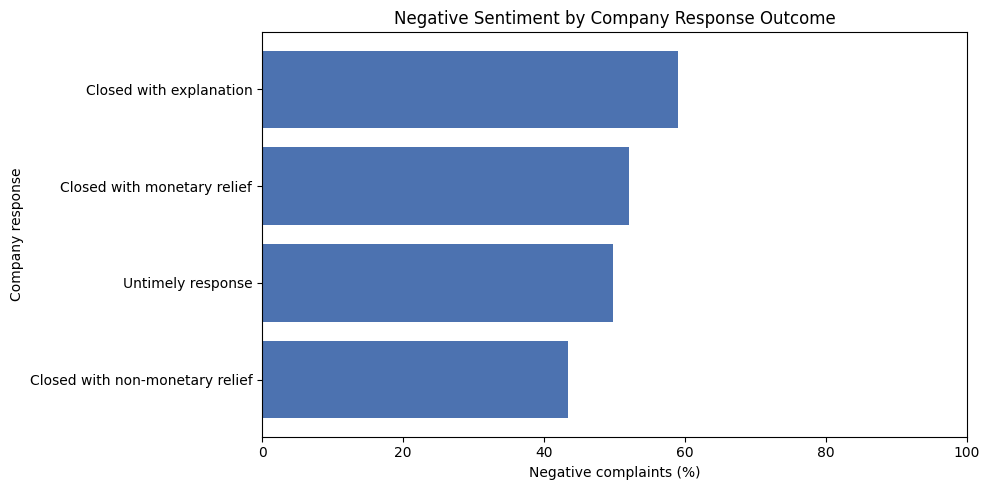

In [47]:
response_plot = (
    response_outcome_summary[
        response_outcome_summary[
            "company_response_to_consumer"
        ] != "In progress"
    ]
    .sort_values("negative_percentage", ascending=True)
)

plt.figure(figsize=(10, 5))

plt.barh(
    response_plot["company_response_to_consumer"],
    response_plot["negative_percentage"],
    color="#4C72B0"
)

plt.title("Negative Sentiment by Company Response Outcome")
plt.xlabel("Negative complaints (%)")
plt.ylabel("Company response")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

## 18. Confidence and Uncertainty Analysis

The confidence score represents how strongly FinBERT preferred its selected label over the alternative labels. It does not measure whether the prediction is objectively correct.

Confidence distributions are examined to distinguish stronger model decisions from uncertain classifications. Because no human-labelled complaint dataset is available, confidence must not be interpreted as accuracy.

In [48]:
confidence_labels = [
    "Low: below 0.50",
    "Moderate: 0.50–0.70",
    "High: 0.70–0.90",
    "Very high: above 0.90"
]

sentiment_enriched["confidence_band"] = pd.cut(
    sentiment_enriched["sentiment_confidence"],
    bins=[0.0, 0.5, 0.7, 0.9, 1.0],
    labels=confidence_labels,
    include_lowest=True
)

overall_confidence_bands = (
    sentiment_enriched["confidence_band"]
    .value_counts(sort=False)
    .rename_axis("confidence_band")
    .reset_index(name="complaints")
)

overall_confidence_bands["percentage"] = (
    overall_confidence_bands["complaints"]
    / len(sentiment_enriched)
    * 100
).round(2)

confidence_by_sentiment = (
    sentiment_enriched
    .groupby(
        ["sentiment_label", "confidence_band"],
        observed=False
    )
    .size()
    .unstack(fill_value=0)
    .reindex(index=SENTIMENT_LABELS)
)

confidence_by_sentiment_percentage = (
    confidence_by_sentiment
    .div(confidence_by_sentiment.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

print("Overall confidence-band distribution")
display(overall_confidence_bands)

print("Confidence-band percentages within each sentiment")
display(confidence_by_sentiment_percentage)

Overall confidence-band distribution


,confidence_band,complaints,percentage
0,Low: below 0.50,7929,2.91
1,Moderate: 0.50–0.70,108237,39.72
2,High: 0.70–0.90,90056,33.05
3,Very high: above 0.90,66244,24.31


Confidence-band percentages within each sentiment


confidence_band,Low: below 0.50,Moderate: 0.50–0.70,High: 0.70–0.90,Very high: above 0.90
sentiment_label,,,,
negative,2.35,32.70,28.97,35.98
neutral,3.69,48.06,39.06,9.20
positive,1.16,97.11,1.40,0.34


### Confidence Interpretation

Only 2.91% of predictions fall below 0.50 confidence, while 57.36% fall within the high or very-high confidence bands. This indicates that FinBERT usually expressed a reasonably clear preference among its three sentiment labels.

Negative predictions are the strongest classifications: 35.98% have very-high confidence and another 28.97% have high confidence. Neutral predictions are more concentrated in the moderate and high bands.

Positive predictions require particular caution. Although positive classifications represent less than 1% of the dataset, 97.11% of them fall within the moderate-confidence range and only 0.34% have very-high confidence. Therefore, the positive category should not be interpreted as reliable evidence of customer satisfaction.

Model confidence measures certainty within FinBERT's own probability distribution. It does not demonstrate correctness. Without human-labelled complaint data, accuracy, precision, recall and F1-score cannot be calculated. All findings in this notebook therefore remain exploratory.

## 19. Saving Sentiment Analysis Outputs

The enriched narrative dataset and analytical summary tables are saved for reuse in the topic-modelling, KPI and SQL notebooks. FinBERT inference will not need to be repeated.

In [49]:
OUTPUT_DIR = Path(
    "/Users/ishika/Documents/AIProject/"
    "data/processed/notebook6_outputs"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Complete narrative dataset with sentiment predictions
sentiment_enriched.to_csv(
    OUTPUT_DIR / "full_narratives_with_sentiment.csv.gz",
    index=False,
    compression="gzip"
)

# Analytical summary tables
company_summary.to_csv(
    OUTPUT_DIR / "company_sentiment_summary.csv",
    index=False
)

issue_summary.to_csv(
    OUTPUT_DIR / "issue_sentiment_summary.csv",
    index=False
)

response_outcome_summary.to_csv(
    OUTPUT_DIR / "response_sentiment_summary.csv",
    index=False
)

timeliness_summary.to_csv(
    OUTPUT_DIR / "timeliness_sentiment_summary.csv",
    index=False
)

overall_confidence_bands.to_csv(
    OUTPUT_DIR / "confidence_band_summary.csv",
    index=False
)

saved_files = pd.DataFrame({
    "file": [
        path.name
        for path in sorted(OUTPUT_DIR.iterdir())
        if path.is_file()
    ],
    "size_mb": [
        round(path.stat().st_size / (1024 ** 2), 2)
        for path in sorted(OUTPUT_DIR.iterdir())
        if path.is_file()
    ]
})

display(saved_files)

,file,size_mb
0,company_sentiment_summary.csv,0.14
1,confidence_band_summary.csv,0.00
2,full_narratives_with_sentiment.csv.gz,146.42
3,issue_sentiment_summary.csv,0.00
4,response_sentiment_summary.csv,0.00
5,timeliness_sentiment_summary.csv,0.00


## 20. Conclusion

This notebook developed an exploratory sentiment-analysis layer for 272,466 CFPB consumer complaint narratives.

Two pretrained models were compared on a balanced 500-narrative sample. FinBERT was selected because its financial-domain training produced more plausible complaint classifications than General DistilBERT, particularly in disagreement cases. General DistilBERT classified several clearly adverse financial complaints as positive.

Long narratives were handled through overlapping token chunks rather than simple truncation. Exact duplicate narratives were processed once and mapped back to their corresponding complaints, reducing full FinBERT inference from 272,466 complaints to 216,031 unique narratives.

### Main Findings

- 56.69% of all narratives were classified as negative.
- 42.55% were classified as neutral.
- Only 0.76% were classified as positive.
- In the equal-product corpus, money-transfer complaints had the highest negative rate at 81.24%.
- Early Warning Services, Block and Navy Federal Credit Union had the highest negative rates among companies with at least 500 narrative complaints, although these results are influenced by product mix.
- “Other transaction problem” combined high volume with a 94.15% negative classification rate.
- Complaints closed with an explanation had a 59.04% negative rate, while complaints receiving non-monetary relief had a rate of 43.38%. These represent associations rather than causal response effects.
- 57.36% of predictions had high or very-high confidence, while 2.91% had confidence below 0.50.
- Positive predictions were rare and predominantly moderate-confidence, so they should not be treated as evidence of customer satisfaction.

### Interpretation Limitation

Agreement between models and high confidence do not prove that a prediction is correct. No human-labelled complaint dataset was created or used; therefore, accuracy, precision, recall and F1-score cannot be measured.

FinBERT was selected through domain suitability, prediction distributions, confidence patterns, model agreement and disagreement analysis, and qualitative inspection—not through supervised accuracy testing.

Consequently, all sentiment findings in this notebook must be interpreted as exploratory model-generated indicators. They are suitable for identifying patterns, prioritising areas for investigation and supporting later financial-intelligence KPIs, but not for making definitive claims about consumer emotion or company performance.

The completed sentiment dataset has been saved for reuse in the topic-modelling, KPI and SQL-analysis stages. FinBERT inference does not need to be repeated.

In [50]:
file_checks = []

for path in sorted(OUTPUT_DIR.glob("*.csv")):
    dataframe = pd.read_csv(path)

    file_checks.append({
        "file": path.name,
        "size_kb": round(path.stat().st_size / 1024, 2),
        "rows": len(dataframe),
        "columns": dataframe.shape[1]
    })

display(pd.DataFrame(file_checks))

,file,size_kb,rows,columns
0,company_sentiment_summary.csv,144.12,2662,8
1,confidence_band_summary.csv,0.16,4,3
2,issue_sentiment_summary.csv,3.41,47,8
3,response_sentiment_summary.csv,0.46,5,8
4,timeliness_sentiment_summary.csv,0.24,2,8
